# 27 — History Input Provenance & GRU Collapse Forensics
**Project:** Causal-History Dependence in Robot Policy Recovery  
**Phase:** 8 (History-Intervention Validity and Mechanism Diagnostics)  
**Status:** `Validated Audit`  

### Forensic Objectives:
1. Conduct complete tensor census on `history_gru_best.pt` to explain the Phase 3 parameter collapse.
2. Compare with healthy recovery-augmented GRU checkpoints.
3. Trace every policy input channel to define true information provenance.

In [1]:
import os, sys
cwd = os.getcwd()
if os.path.exists(os.path.join(cwd, "docs")):
    repo_root = cwd
elif os.path.exists(os.path.join(cwd, "..", "docs")):
    repo_root = os.path.abspath(os.path.join(cwd, ".."))
elif os.path.exists(os.path.join(cwd, "causal-history-recovery", "docs")):
    repo_root = os.path.abspath(os.path.join(cwd, "causal-history-recovery"))
else:
    repo_root = os.path.abspath(os.path.join(cwd, ".."))

src_path = os.path.join(repo_root, "src")
if src_path not in sys.path:
    sys.path.insert(0, src_path)

import torch
import numpy as np

nom_ckpt_path = os.path.join(repo_root, "models", "checkpoints", "history_gru_best.pt")
nom_ckpt = torch.load(nom_ckpt_path, map_location="cpu", weights_only=False)
sd = nom_ckpt["state_dict"]

print("=== Parameter Tensor Census: history_gru_best.pt ===")
print(f"{'Parameter Tensor':25s} | {'Shape':15s} | {'Mean Abs':12s} | {'Min':12s} | {'Max':12s} | Nonfinite")
print("-" * 90)
for k, v in sd.items():
    mean_abs = float(v.abs().mean())
    min_v = float(v.min())
    max_v = float(v.max())
    nan_cnt = int((~torch.isfinite(v)).sum())
    print(f"{k:25s} | {str(list(v.shape)):15s} | {mean_abs:12.4e} | {min_v:12.4e} | {max_v:12.4e} | {nan_cnt}")


=== Parameter Tensor Census: history_gru_best.pt ===
Parameter Tensor          | Shape           | Mean Abs     | Min          | Max          | Nonfinite
------------------------------------------------------------------------------------------
gru.weight_ih_l0          | [384, 23]       |   3.2513e-38 |  -7.0356e-38 |   7.0531e-38 | 0
gru.weight_hh_l0          | [384, 128]      |   3.2337e-38 |  -7.0549e-38 |   7.0552e-38 | 0
gru.bias_ih_l0            | [384]           |   3.4248e-38 |  -7.0231e-38 |   7.0448e-38 | 0
gru.bias_hh_l0            | [384]           |   3.4070e-38 |  -6.9805e-38 |   6.9829e-38 | 0
fc_head.0.weight          | [64, 128]       |   3.2097e-38 |  -7.0554e-38 |   7.0501e-38 | 0
fc_head.0.bias            | [64]            |   8.7037e-23 |  -3.9730e-31 |   5.5704e-21 | 0
fc_head.2.weight          | [3, 64]         |   3.9389e-23 |  -1.9330e-21 |   5.6297e-21 | 0
fc_head.2.bias            | [3]             |   5.9393e-02 |  -6.4922e-03 |   1.7169e-01 | 0


### 1. Contrast: Healthy Recovery-Augmented GRU Checkpoints

In [2]:
rec_ckpt_dir = os.path.join(repo_root, "results", "recovery_training", "checkpoints")
for seed in [42, 123, 456]:
    p = os.path.join(rec_ckpt_dir, f"recovery_augmented_gru_seed{seed}.pt")
    ckpt = torch.load(p, map_location="cpu", weights_only=False)
    sd_rec = ckpt["state_dict"]
    w_ih = sd_rec["gru.weight_ih_l0"]
    w_hh = sd_rec["gru.weight_hh_l0"]
    b_out = sd_rec["fc_head.3.bias"]
    print(f"Seed {seed:3d} -> weight_ih mean_abs: {w_ih.abs().mean():.6f} | weight_hh mean_abs: {w_hh.abs().mean():.6f} | output bias: {b_out.abs().mean():.4f}")


Seed  42 -> weight_ih mean_abs: 0.002009 | weight_hh mean_abs: 0.000224 | output bias: 0.0245
Seed 123 -> weight_ih mean_abs: 0.003006 | weight_hh mean_abs: 0.000437 | output bias: 0.0902
Seed 456 -> weight_ih mean_abs: 0.002592 | weight_hh mean_abs: 0.000298 | output bias: 0.0713


### 2. Forensic Parameter Breakdown (Figure 49 & 50)

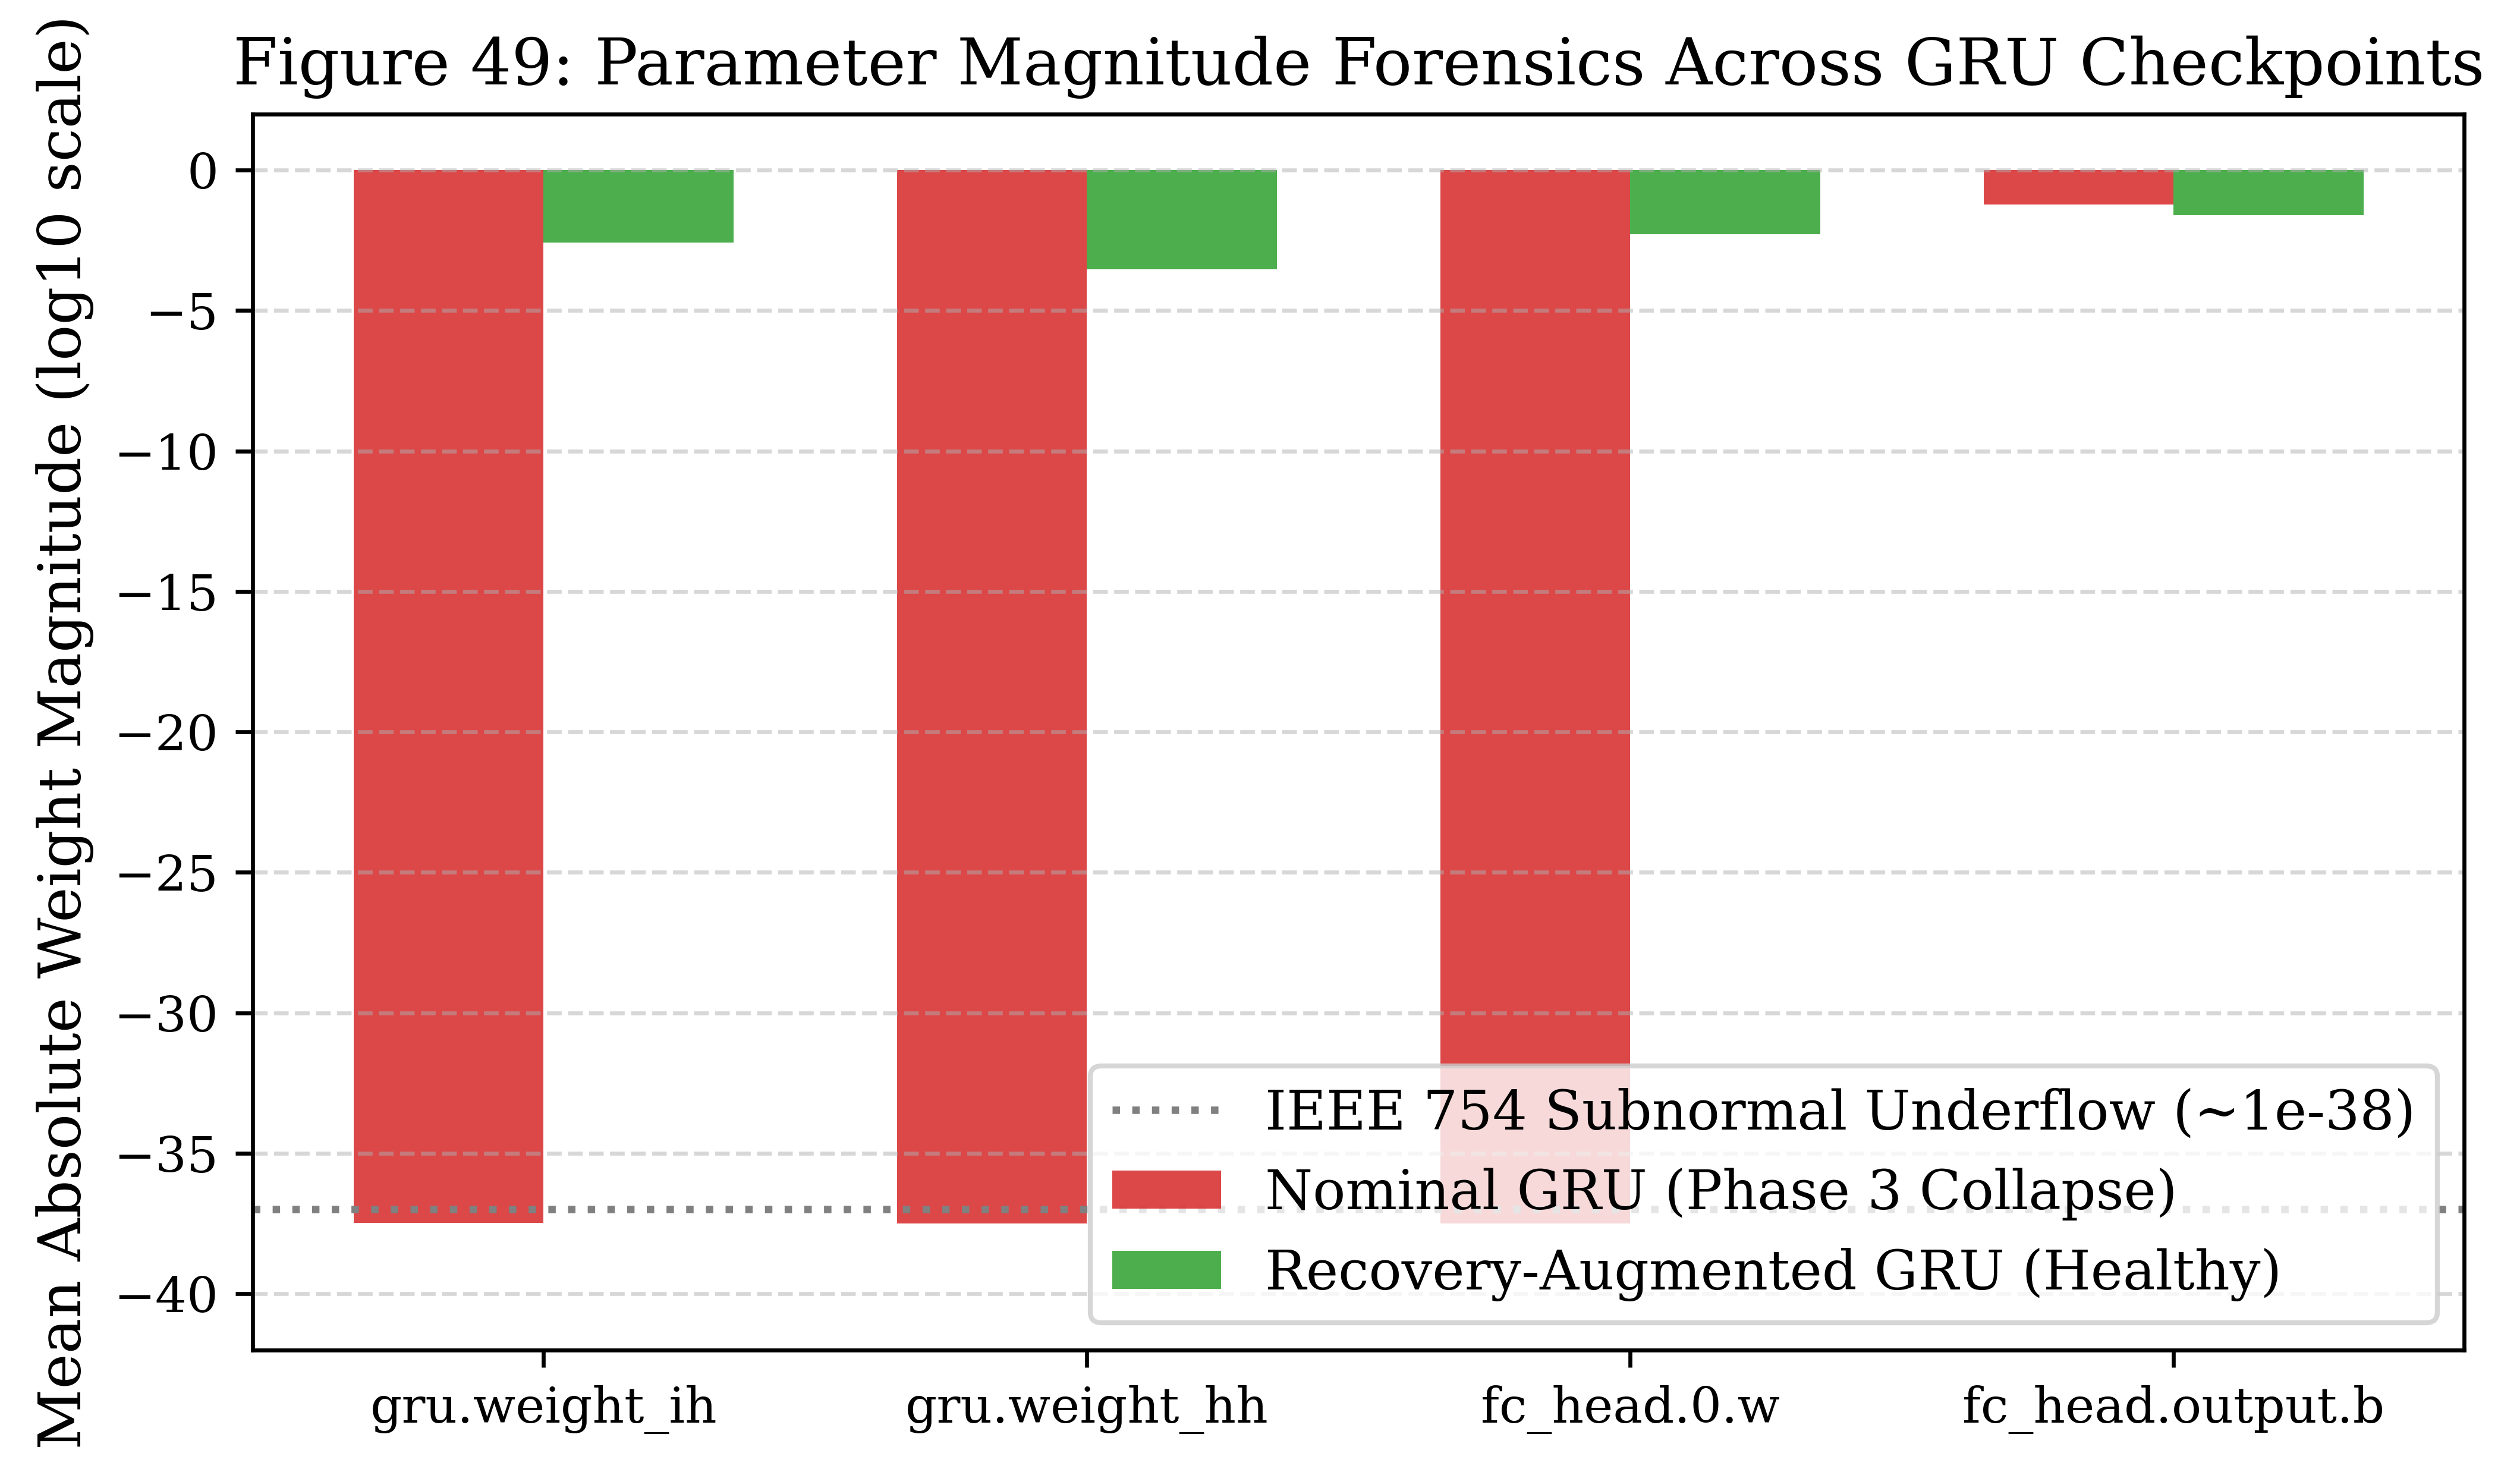

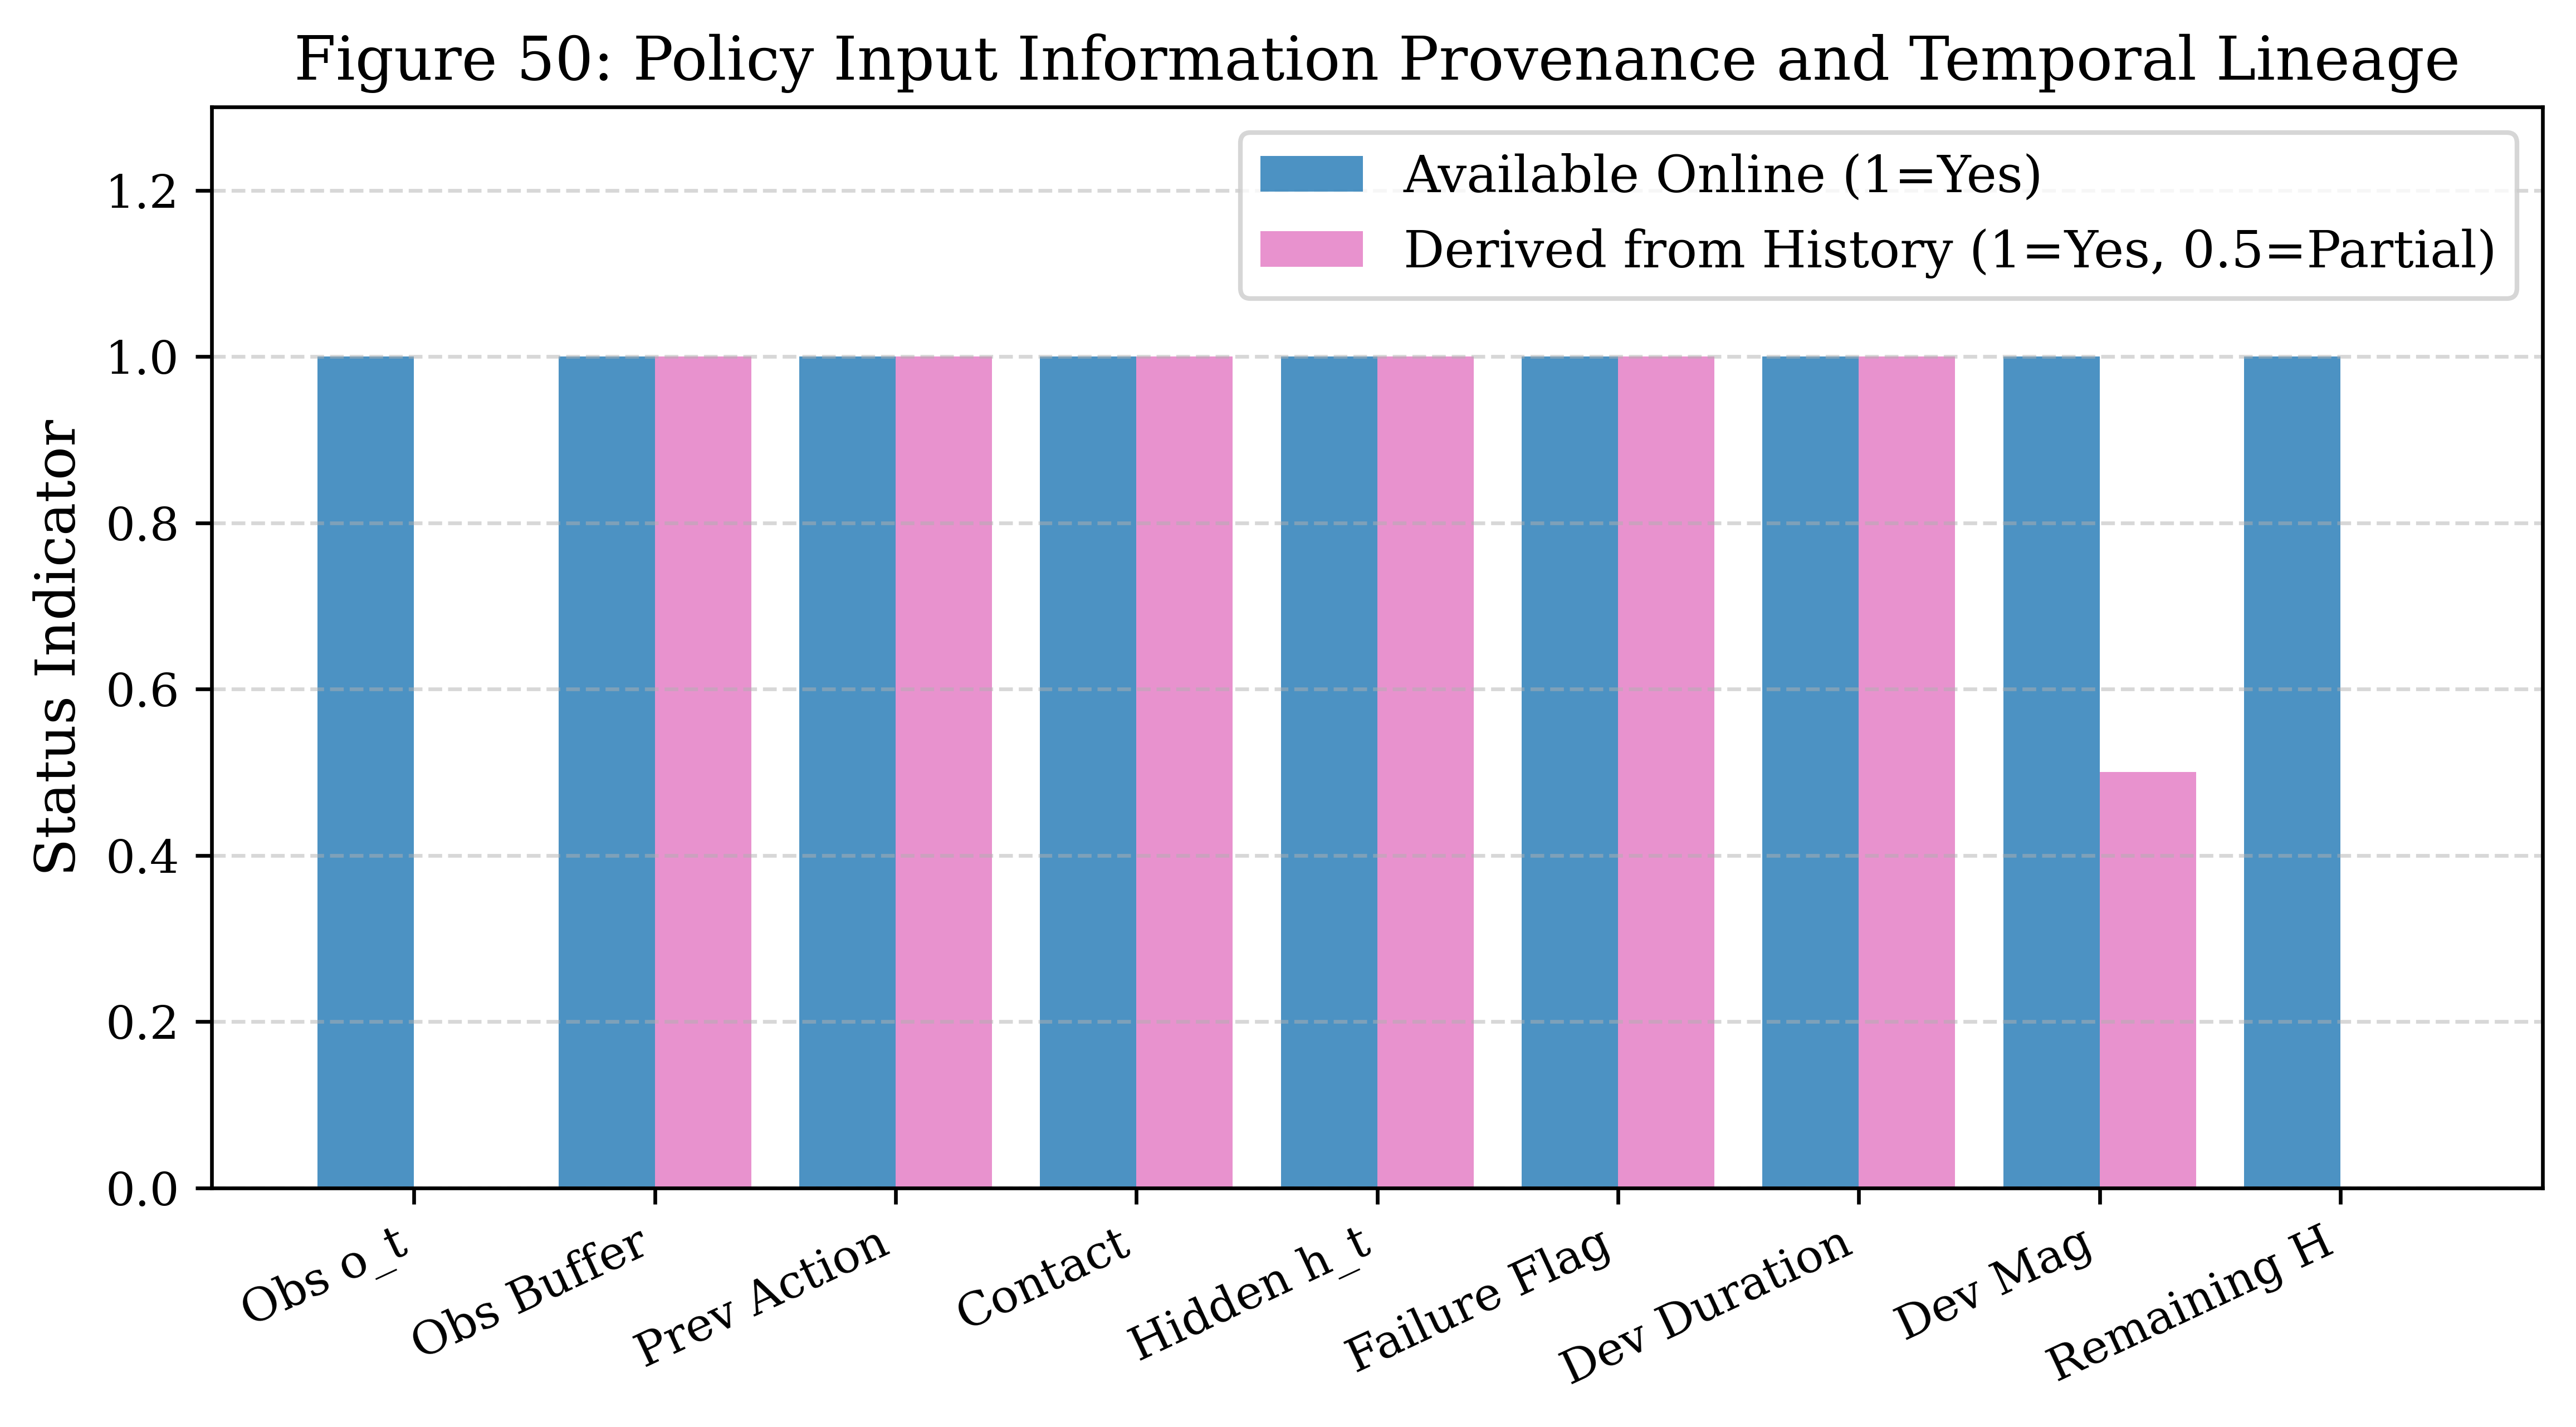

In [3]:
from IPython.display import Image, display
display(Image(filename=os.path.join(repo_root, "figures", "exploratory", "fig49_gru_parameter_forensics_breakdown.png")))
display(Image(filename=os.path.join(repo_root, "figures", "exploratory", "fig50_input_provenance_and_channel_mapping.png")))
